# Exercise: Model selection and resampling

**Course:** BERN02  
**Author:** Tao Ran  

This notebook studies predictive model assessment using a validation set, K-fold cross-validation, and the bootstrap.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error
from scipy.optimize import minimize

plt.rcParams['figure.figsize'] = (8, 5)


## 1. Load the air pollution data

The response variable is mortality (`MORT`) and the predictor is average July temperature in degrees Fahrenheit (`JULT`).

In [14]:
pollution = pd.read_csv('pollution_cleaneddata.csv')
pollution.head()


,PREC,JANT,JULT,OVR65,POPN,EDUC,HOUS,DENS,NONW,WWDRK,POOR,HC,NOX,SO@,HUMID,MORT
0,36.0,27.0,71.0,8.1,3.34,11.4,81.5,3243.0,8.8,42.6,11.7,21.0,15.0,59.0,59.0,921.870
1,35.0,23.0,72.0,11.1,3.14,11.0,78.8,4281.0,3.5,50.7,14.4,8.0,10.0,39.0,57.0,997.875
2,44.0,29.0,74.0,10.4,3.21,9.8,81.6,4260.0,0.8,39.4,12.4,6.0,6.0,33.0,54.0,962.354
3,47.0,45.0,79.0,6.5,3.41,11.1,77.5,3125.0,27.1,50.2,20.6,18.0,8.0,24.0,56.0,982.291
4,43.0,35.0,77.0,7.6,3.44,9.6,84.6,6441.0,24.4,43.7,14.3,43.0,38.0,206.0,55.0,1071.289


In [15]:
print('Shape:', pollution.shape)
print('\nVariables:')
print(pollution.columns.tolist())
print('\nMissing values in variables used:')
print(pollution[['JULT', 'MORT']].isna().sum())


Shape: (60, 16)

Variables:
['PREC', 'JANT', 'JULT', 'OVR65', 'POPN', 'EDUC', 'HOUS', 'DENS', 'NONW', 'WWDRK', 'POOR', 'HC', 'NOX', 'SO@', 'HUMID', 'MORT']

Missing values in variables used:
JULT    0
MORT    0
dtype: int64


## 2. Validation set approach

I split the observations randomly into equally sized training and test sets. Polynomial regression models of degree 1 to 4 are fitted to the training data. For each model I calculate the mean squared error (MSE) on both the training and test data.

For a polynomial of degree $d$ the model is

$$MORT_i = \beta_0 + \beta_1 JULT_i + \beta_2 JULT_i^2 + \cdots + \beta_d JULT_i^d + \epsilon_i.$$

In [16]:
X = pollution[['JULT']].to_numpy()
y = pollution['MORT'].to_numpy()

seed = 123
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=seed
)

degrees = range(1, 5)
train_mse = []
test_mse = []

for degree in degrees:
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    train_mse.append(mean_squared_error(y_train, model.predict(X_train_poly)))
    test_mse.append(mean_squared_error(y_test, model.predict(X_test_poly)))

validation_results = pd.DataFrame({
    'Degree': list(degrees),
    'Training MSE': train_mse,
    'Testing MSE': test_mse
})
validation_results


,Degree,Training MSE,Testing MSE
0,1,2866.993299,4703.889138
1,2,2851.748712,4413.295764
2,3,1886.100371,4494.869377
3,4,1876.489172,4592.139716


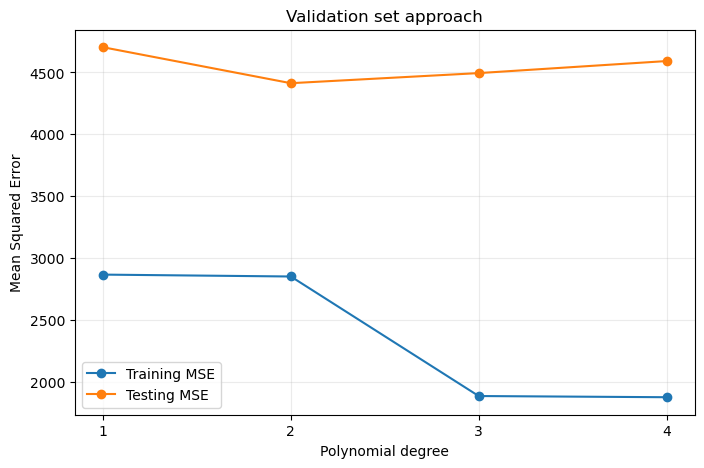

Degree with smallest test MSE: 2


In [17]:
plt.plot(validation_results['Degree'], validation_results['Training MSE'], marker='o', label='Training MSE')
plt.plot(validation_results['Degree'], validation_results['Testing MSE'], marker='o', label='Testing MSE')
plt.xlabel('Polynomial degree')
plt.ylabel('Mean Squared Error')
plt.title('Validation set approach')
plt.xticks([1, 2, 3, 4])
plt.legend()
plt.grid(alpha=0.25)
plt.show()

best_degree = validation_results.loc[validation_results['Testing MSE'].idxmin(), 'Degree']
print('Degree with smallest test MSE:', int(best_degree))


### Interpretation

The training MSE generally decreases as model complexity increases, because more flexible models can fit the training observations more closely. The test MSE is more important for prediction of new observations. I would prefer the degree with the lowest test MSE, while avoiding unnecessary polynomial complexity. A very flexible model can have larger prediction variance and may overfit the training sample.

## 3. Repeat the validation approach with ten seeds

A single validation split can depend strongly on which observations happen to be assigned to the training and test sets. I therefore repeat the procedure using ten random seeds.

In [18]:
seeds = range(1, 11)
all_results = []

for seed in seeds:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.5, random_state=seed
    )

    for degree in range(1, 5):
        poly = PolynomialFeatures(degree=degree, include_bias=False)
        X_train_poly = poly.fit_transform(X_train)
        X_test_poly = poly.transform(X_test)

        model = LinearRegression().fit(X_train_poly, y_train)

        all_results.append({
            'Seed': seed,
            'Degree': degree,
            'Training MSE': mean_squared_error(y_train, model.predict(X_train_poly)),
            'Testing MSE': mean_squared_error(y_test, model.predict(X_test_poly))
        })

repeated_validation = pd.DataFrame(all_results)
repeated_validation


,Seed,Degree,Training MSE,Testing MSE
0,1,1,2545.297540,5040.756601
1,1,2,1725.969873,6264.876170
2,1,3,1579.549097,4503.027465
3,1,4,1432.911404,18958.881016
4,2,1,3741.839939,3478.233759
5,2,2,2303.107520,6425.207260
6,2,3,2244.308297,4448.747104
7,2,4,2136.810187,5675.699849
8,3,1,3503.976595,3667.911949
9,3,2,3213.486241,3508.538872


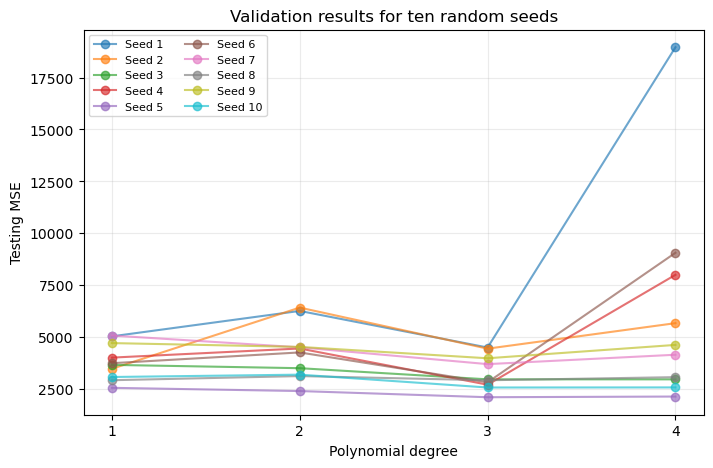

Mean test MSE by degree:


,mean,std
Degree,,
1,3832.598024,880.711448
2,4270.324225,1303.309892
3,3277.325650,826.145968
4,6126.140346,5064.378050


Best degree for each seed:


,Seed,Degree,Testing MSE
2,1,3,4503.027465
4,2,1,3478.233759
11,3,4,2970.789361
14,4,3,2713.454582
18,5,3,2110.844327
22,6,3,2828.417874
26,7,3,3704.058798
30,8,3,2927.527951
34,9,3,3986.232326
38,10,3,2578.987079


In [19]:
for seed in seeds:
    temp = repeated_validation[repeated_validation['Seed'] == seed]
    plt.plot(temp['Degree'], temp['Testing MSE'], marker='o', alpha=0.65, label=f'Seed {seed}')

plt.xlabel('Polynomial degree')
plt.ylabel('Testing MSE')
plt.title('Validation results for ten random seeds')
plt.xticks([1, 2, 3, 4])
plt.legend(ncol=2, fontsize=8)
plt.grid(alpha=0.25)
plt.show()

print('Mean test MSE by degree:')
display(repeated_validation.groupby('Degree')['Testing MSE'].agg(['mean', 'std']))

print('Best degree for each seed:')
best_by_seed = repeated_validation.loc[
    repeated_validation.groupby('Seed')['Testing MSE'].idxmin(), ['Seed', 'Degree', 'Testing MSE']
]
display(best_by_seed)


### Interpretation

The results are not exactly the same for all seeds. This is expected because changing the seed changes which observations are placed in the training and test sets. With only 60 observations, a 50/50 split leaves only 30 observations in each set, so the estimated test error can vary noticeably between splits. The overall comparison of simple and more flexible models is more informative than relying on only one random split.

## 4. K-fold cross-validation

I use a degree-2 polynomial as an example and 10-fold cross-validation. Each observation is used for validation once, while the remaining folds are used for training. The MSE is calculated for every held-out fold. The variation among these held-out prediction errors provides information about the variability of predictive performance.

In [20]:
degree = 2
K = 10
seed = 123

kf = KFold(n_splits=K, shuffle=True, random_state=seed)
fold_mse = []

for train_index, test_index in kf.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression().fit(X_train_poly, y_train)
    predictions = model.predict(X_test_poly)
    fold_mse.append(mean_squared_error(y_test, predictions))

print('Fold MSE values:', np.round(fold_mse, 2))
print('Mean CV MSE:', np.mean(fold_mse))
print('Variance of fold MSE:', np.var(fold_mse, ddof=1))


Fold MSE values: [6063.18 6235.43 3082.86 2781.58 2422.11 3563.52 7668.61 1941.67 4200.85
 1849.93]
Mean CV MSE: 3980.9734835210847
Variance of fold MSE: 4068309.853550597


### Repeat K-fold CV with ten seeds


In [21]:
cv_results = []

for seed in range(1, 11):
    kf = KFold(n_splits=K, shuffle=True, random_state=seed)
    fold_mse = []

    for train_index, test_index in kf.split(X):
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = y[train_index], y[test_index]

        poly = PolynomialFeatures(degree=degree, include_bias=False)
        X_train_poly = poly.fit_transform(X_train)
        X_test_poly = poly.transform(X_test)

        model = LinearRegression().fit(X_train_poly, y_train)
        fold_mse.append(mean_squared_error(y_test, model.predict(X_test_poly)))

    cv_results.append({
        'Seed': seed,
        'Mean CV MSE': np.mean(fold_mse),
        'Variance of fold MSE': np.var(fold_mse, ddof=1)
    })

cv_results = pd.DataFrame(cv_results)
cv_results


,Seed,Mean CV MSE,Variance of fold MSE
0,1,4747.571565,2.174839e+07
1,2,3625.103942,8.268370e+06
2,3,3613.975113,7.463719e+06
3,4,3578.747033,3.640955e+06
4,5,3721.492061,7.494678e+06
5,6,4695.570762,1.177145e+07
6,7,3636.864493,1.465196e+06
7,8,3677.307978,4.516659e+06
8,9,3913.701609,5.861172e+06
9,10,3504.538151,5.805535e+06


Mean of the ten CV MSE estimates: 3871.487270712975
SD of the ten CV MSE estimates: 460.80088606506087


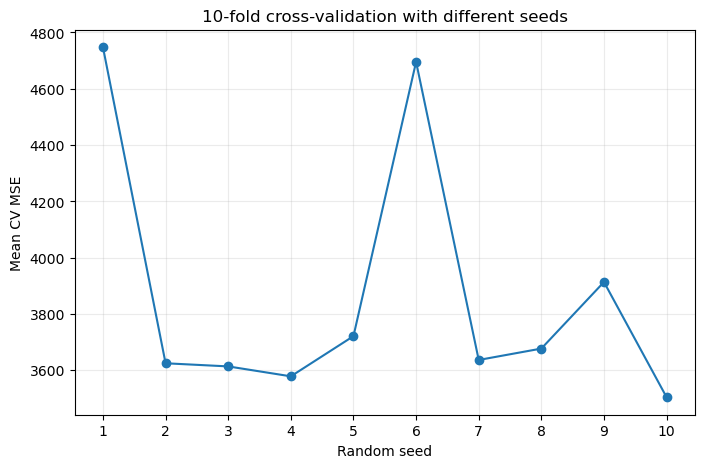

In [22]:
print('Mean of the ten CV MSE estimates:', cv_results['Mean CV MSE'].mean())
print('SD of the ten CV MSE estimates:', cv_results['Mean CV MSE'].std())

plt.plot(cv_results['Seed'], cv_results['Mean CV MSE'], marker='o')
plt.xlabel('Random seed')
plt.ylabel('Mean CV MSE')
plt.title('10-fold cross-validation with different seeds')
plt.xticks(range(1, 11))
plt.grid(alpha=0.25)
plt.show()


### Interpretation

The K-fold estimates should generally be more similar across random seeds than estimates from a single 50/50 validation split. In K-fold cross-validation, every observation is used for validation and most observations are used for training in each fit. Therefore the estimate uses the available data more efficiently and is less dependent on one particular train/test split. Some variation remains because the random seed changes the allocation of observations to folds.

## 5. Bootstrap: standard error of the Poisson regression slope

The bird counts are modeled using a Poisson regression. Let $Y_i$ denote the bird count in year $i$. I assume

$$Y_i \sim \mathrm{Poisson}(\lambda_i),$$

with log link

$$\log(\lambda_i)=\beta_0+\beta_1 x_i.$$

The slope $\beta_1$ represents the change in log expected bird count associated with a one-year increase. As in the earlier exercise, I estimate the parameters by writing the Poisson negative log-likelihood and using a numerical optimizer rather than a ready-made Poisson regression function.

In [23]:
birds = pd.read_csv('bird_count.csv')
birds


,count,yr,observerAge,lineCov
0,2,2011,63,1.000000
1,5,2010,64,0.987500
2,12,2002,30,0.991667
3,12,2006,60,0.987500
4,5,2008,62,0.987500
5,12,2012,64,1.000000
6,5,2000,28,0.991667
7,8,2005,59,0.987500
8,9,2007,61,0.987500
9,14,2004,58,1.000000


In [24]:
def fit_poisson(data):
    y_bird = data['count'].to_numpy()
    # Centering year improves numerical stability. It does not change the slope.
    x_bird = data['yr'].to_numpy() - data['yr'].mean()

    def negative_log_likelihood(beta):
        eta = beta[0] + beta[1] * x_bird
        mu = np.exp(eta)
        # log(y!) is omitted because it is constant with respect to beta.
        return np.sum(mu - y_bird * eta)

    start = np.array([np.log(y_bird.mean()), 0.0])
    result = minimize(negative_log_likelihood, start, method='BFGS')
    return result.x

beta_hat = fit_poisson(birds)
print('Intercept (with centered year):', beta_hat[0])
print('Slope:', beta_hat[1])


Intercept (with centered year): 2.108212163533401
Slope: -0.03244316741958529


### Bootstrap procedure

I sample rows of the original bird data with replacement. Each bootstrap data set has the same number of observations as the original data. I refit the Poisson model to each bootstrap sample and save the slope estimate. The bootstrap standard error is the sample standard deviation of these slope estimates.

In [25]:
B = 10000
rng = np.random.default_rng(123)
bootstrap_slopes = np.empty(B)

for b in range(B):
    indices = rng.integers(0, len(birds), size=len(birds))
    bootstrap_sample = birds.iloc[indices].reset_index(drop=True)
    bootstrap_slopes[b] = fit_poisson(bootstrap_sample)[1]

bootstrap_se = np.std(bootstrap_slopes, ddof=1)

print('Original slope estimate:', beta_hat[1])
print('Bootstrap standard error:', bootstrap_se)
print('Teacher reference value: 0.034212')


Original slope estimate: -0.03244316741958529
Bootstrap standard error: 0.03384813322375502
Teacher reference value: 0.034212


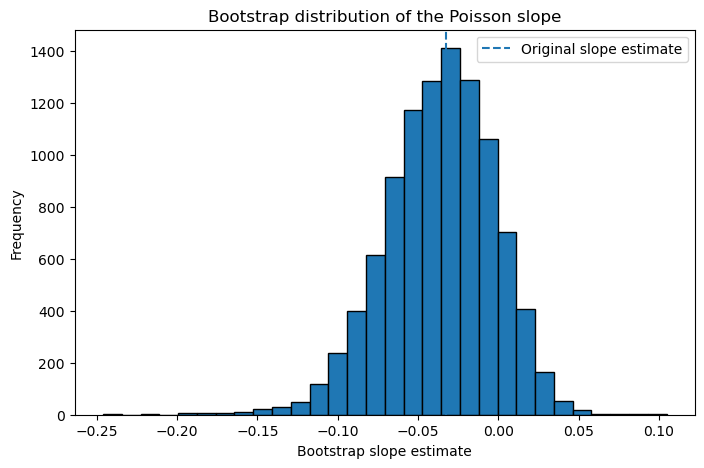

In [26]:
plt.hist(bootstrap_slopes, bins=30, edgecolor='black')
plt.axvline(beta_hat[1], linestyle='--', label='Original slope estimate')
plt.xlabel('Bootstrap slope estimate')
plt.ylabel('Frequency')
plt.title('Bootstrap distribution of the Poisson slope')
plt.legend()
plt.show()


### Bootstrap interpretation

With 10,000 bootstrap samples and seed 123, the estimated standard error should be close to **0.034**. It does not have to equal the reference value 0.034212 exactly because bootstrap results depend slightly on the random seed and the finite number of bootstrap samples. The close agreement indicates that the bootstrap implementation gives the expected uncertainty for the slope estimate.

## 6. Conclusion

The validation-set exercise demonstrates that estimates of prediction error can depend on a particular random train/test split, especially for a relatively small data set. Increasing polynomial complexity always makes it possible to fit the training data at least as closely, but this does not guarantee better prediction of new observations.

K-fold cross-validation makes more efficient use of the data because every observation is used for validation and training across the different folds. Consequently, the estimated predictive performance is generally less dependent on one particular split.

Finally, the bootstrap provides a simple resampling-based estimate of uncertainty in the Poisson regression coefficient. The bootstrap standard error of the bird-count slope is approximately 0.034, close to the reference value given in the exercise.